# ESKİ — Temizleme Denemeleri (arşiv)

> **Bu defter yalnızca geliştirme geçmişidir.** Temizleme artık tek yerde yapılıyor: `src/temizle.py`.
> Buradaki kod, eski ara dosyaları (`arac_verisi_temiz.csv`, `arac_temiz_v2.csv`) üretir ve güncel sonuçla uyuşmaz.


In [3]:
import pandas as pd
import numpy as np

# 1. Ham veriyi yükle
df = pd.read_csv("../data/raw/arac_verisi.csv")
print(f"Temizlik öncesi ilan sayısı: {len(df)}")

# 2. Tekrar eden (kopya) satırları uçur
df = df.drop_duplicates()

# 3. Klasik araçları (1995 öncesi) kapsam dışı bırak
df = df[df["year"] >= 1995]

# 4. Hatalı şehirleri ("Diğer", "Kardzhali") çıkar
df = df[~df["city"].isin(["Diğer", "Kardzhali"])]

# 5. Makine öğrenmesi modelimiz için fiyatın logaritmasını alarak yeni bir sütun türet
df["log_price"] = np.log(df["price"])

print(f"Temizlik sonrası sağlıklı ilan sayısı: {len(df)}")

# 6. Pırıl pırıl olmuş bu yeni veriyi processed (işlenmiş) klasörüne kaydet
df.to_csv("../data/processed/arac_verisi_temiz.csv", index=False)
print("Temizlenmiş veri başarıyla kaydedildi! Aşama 3 başladı.")

Temizlik öncesi ilan sayısı: 253344
Temizlik sonrası sağlıklı ilan sayısı: 251460
Temizlenmiş veri başarıyla kaydedildi! Aşama 3 başladı.


In [2]:
import pandas as pd

# Eğer baştan açtıysan temiz verimizi tekrar yüklüyoruz
df_clean = pd.read_csv("../data/processed/arac_verisi_temiz.csv")

# Neden yapıyoruz?: variant sütununda "1.6 TDI", "1.4 TSI" gibi paket adları var. 
# "TDI" dizel demek, "TSI" benzin demek. Bu kelimeleri avlayıp yeni bir "yakit_tipi" sütunu yaratacağız.

def yakit_turet(variant):
    variant = str(variant).upper() # Hepsini büyük harfe çevir ki kelimeleri kaçırmayalım
    
    dizel_kelimeler = ['TDI', 'DCI', 'HDI', 'CDTI', 'CRDI', 'BLUEHDI', 'MULTIJET', 'D-4D', 'TDCI', 'D']
    benzin_kelimeler = ['TSI', 'TFSI', 'VTI', 'CGI', 'PURETECH', 'ECOBOOST', 'MPI', 'IG-T', 'T-GDI']
    
    if 'LPG' in variant or 'ECOG' in variant:
        return 'LPG'
    elif any(kelime in variant for kelime in dizel_kelimeler):
        return 'Dizel'
    elif any(kelime in variant for kelime in benzin_kelimeler):
        return 'Benzin'
    else:
        # Eğer özel bir kısaltma yoksa genelde standart atmosferik benzinli araçlardır
        return 'Belirsiz/Benzin' 

# Fonksiyonu tüm satırlara uygulayıp yeni sütunumuzu yaratıyoruz
df_clean["yakit_tipi"] = df_clean["variant"].apply(yakit_turet)

# Çıkan sonuca bakalım:
print(df_clean["yakit_tipi"].value_counts())

yakit_tipi
Dizel              138281
Belirsiz/Benzin     87414
Benzin              25765
Name: count, dtype: int64


In [2]:
import pandas as pd

raw = pd.read_csv("../data/raw/arac_verisi.csv")
clean = pd.read_csv("../data/processed/arac_verisi_temiz.csv")

print("Ham:", len(raw), "| Temiz:", len(clean), "| Fark:", len(raw) - len(clean))
print("Mükerrer:", raw.duplicated().sum())
print("km == 0:", (raw["km"] == 0).sum())
print("year < 1995:", (raw["year"] < 1995).sum())

# Fiyat tavanı ve tabanı
print("\nprice == 10.000.000:", (raw["price"] == 10_000_000).sum())
print("price == 100.000:", (raw["price"] == 100_000).sum())
print("km == 0 VE price == 10M:", ((raw["km"] == 0) & (raw["price"] == 10_000_000)).sum())
print("Temiz veride price == 10M:", (clean["price"] == 10_000_000).sum())

Ham: 253344 | Temiz: 251460 | Fark: 1884
Mükerrer: 288
km == 0: 101
year < 1995: 1593

price == 10.000.000: 546
price == 100.000: 80
km == 0 VE price == 10M: 93
Temiz veride price == 10M: 504


In [5]:
# Yakıt tipini türeten fonksiyonu temiz verimize uygulayalım
def yakit_turet(variant):
    variant = str(variant).upper()
    dizel_kelimeler = ['TDI', 'DCI', 'HDI', 'CDTI', 'CRDI', 'BLUEHDI', 'MULTIJET', 'D-4D', 'TDCI', 'D']
    benzin_kelimeler = ['TSI', 'TFSI', 'VTI', 'CGI', 'PURETECH', 'ECOBOOST', 'MPI', 'IG-T', 'T-GDI']
    
    if 'LPG' in variant or 'ECOG' in variant:
        return 'LPG'
    elif any(kelime in variant for kelime in dizel_kelimeler):
        return 'Dizel'
    elif any(kelime in variant for kelime in benzin_kelimeler):
        return 'Benzin'
    else:
        return 'Belirsiz/Benzin'

clean["yakit_tipi"] = clean["variant"].apply(yakit_turet)

# Şimdi Blok 2'yi tekrar çalıştırabilirsin:
print(clean["yakit_tipi"].value_counts(dropna=False))

for tip in clean["yakit_tipi"].dropna().unique():
    print(f"\n== {tip} ==")
    print(clean[clean["yakit_tipi"] == tip]["variant"].sample(min(15, len(clean[clean["yakit_tipi"] == tip])), random_state=1).tolist())

print("\nMarka Bazında Yakıt Dağılımı (İlk 12 Marka):")
print(pd.crosstab(clean["brand"], clean["yakit_tipi"], normalize="index").round(2).head(12))

yakit_tipi
Dizel              138281
Belirsiz/Benzin     87414
Benzin              25765
Name: count, dtype: int64

== Benzin ==
['1.2 PureTech Access', '1.4 TSI Sportline', 'A3 Hatchback 1.4 TFSI', '1.2 MPI Elite', '1.0 MPI Cool', '1.4 TSI Exclusive', '1.4 TSI Highline', '1.4 TSI BlueMotion Highline', '1.5 TSI  Impression', '1.5 TSI R Line', '1.2 TSI Comfortline', '1.2 Puretech Style Tech', '1.2 TSI Comfortline', 'A5 Sportback 1.4 TFSI Sport', '1.4 TSI Allstar']

== Dizel ==
['1.6 TDI BlueMotion Business', '1.3 Multijet Dynamic', '1.0 D-CVVT Style', '1.6 TDCi Style', '1.5 BlueDCI Joy', '1.3 Admire', '1.6 Multijet Easy', '1.2 TSI BlueMotion Trendline', 'A5 Sportback 2.0 TDI Quattro', '1.6 CDTI Sport', '1.3 Multijet Pop', 'A4 Sedan 1.4 TFSI Dynamic', '1.3 CDTI Sport', '1.5 BlueHDI Feel', '1.4 D-4D Premium']

== Belirsiz/Benzin ==
['1.4 SX', '1.0 TCe Joy', '520i M Sport', '1.5 EcoBlue Titanium X', '1.2 Twinport Essentia', '1.4 CVVT Comfort', '1.4 Fire Easy', '1.6i VTEC Eco Elegance', '1.

In [4]:
def yakit_turet_gelismis(variant):
    variant_str = str(variant).upper()
    
    # Önce net LPG ve Hibrit/Elektrik ipuçları
    if 'LPG' in variant_str or 'ECOG' in variant_str or 'VTEC ECO' in variant_str:
        return 'LPG'
    elif 'HYBRID' in variant_str or 'HIBRIT' in variant_str or 'ELECTRIC' in variant_str or 'EV' in variant_str:
        return 'Hibrit/Elektrik'
        
    # Kesin Benzinli anahtar kelimeleri (TSI'ın dizele kaçmasını önlemek için önce benzinliyi kontrol ediyoruz)
    benzin_kelimeler = ['TSI', 'TFSI', 'VTI', 'CGI', 'PURETECH', 'ECOBOOST', 'MPI', 'IG-T', 'T-GDI', 'TCe', 'FSI', 'GDI', 'KOMPRESSOR', 'VTEC']
    if any(kelime in variant_str for kelime in benzin_kelimeler):
        return 'Benzin'
        
    # Kesin Dizel anahtar kelimeleri (İçinde ' D ' geçip benzinli olmayanlar için dikkatli filtreleme)
    dizel_kelimeler = ['TDI', 'DCI', 'HDI', 'CDTI', 'CRDI', 'BLUEHDI', 'MULTIJET', 'D-4D', 'TDCI', 'ECOBLUE', 'SKYACTIV-D']
    if any(kelime in variant_str for kelime in dizel_kelimeler):
        return 'Dizel'
        
    # Eğer hâlâ eşleşmediyse ancak içinde sadece 'D' veya 'DIESEL' geçiyorsa
    if 'DIESEL' in variant_str or ' D ' in variant_str or variant_str.endswith(' D'):
        return 'Dizel'
    
    # Hiçbiri tutmazsa standart benzin/atmosferik kabul edelim
    return 'Belirsiz/Benzin'

# Gelişmiş fonksiyonumuzu temiz verimize uygulayalım
clean["yakit_tipi"] = clean["variant"].apply(yakit_turet_gelismis)

# Yeni dağılıma bakalım:
print("--- Güncellenmiş Yakıt Tipi Dağılımı ---")
print(clean["yakit_tipi"].value_counts(dropna=False))

--- Güncellenmiş Yakıt Tipi Dağılımı ---
yakit_tipi
Belirsiz/Benzin    104575
Dizel              103387
Benzin              35988
LPG                  4056
Hibrit/Elektrik      3454
Name: count, dtype: int64


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Temiz verimizi yükleyelim (eğer farklı bir notebook'ta çalışıyorsan)
# clean = pd.read_csv("../data/processed/arac_temiz_v1.csv") -> yakit_tiplerini kaydettiysen doğrudan o dosyayı da okutabilirsin.

# Model performansını artıracak log(fiyat) sütununu ekleyelim
clean["log_price"] = np.log(clean["price"])

# Sayısal sütunlar arasındaki korelasyon matrisine bakalım
numeric_cols = ["price", "log_price", "km", "year"]
corr_matrix = clean[numeric_cols].corr()

print("--- Sayısal Değişkenler Korelasyon Matrisi ---")
print(corr_matrix.round(3))

--- Sayısal Değişkenler Korelasyon Matrisi ---
           price  log_price     km   year
price      1.000      0.856 -0.435  0.508
log_price  0.856      1.000 -0.552  0.738
km        -0.435     -0.552  1.000 -0.661
year       0.508      0.738 -0.661  1.000


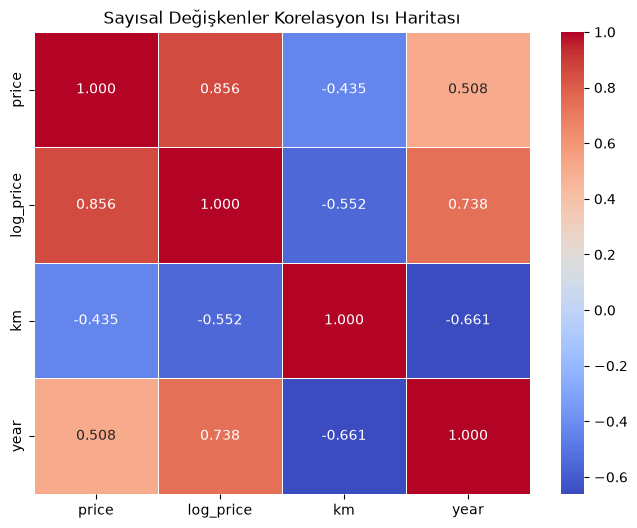

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Sayısal sütunlar üzerinden korelasyon matrisini tekrar tanımlayalım
numeric_cols = ["price", "log_price", "km", "year"]
corr_matrix = clean[numeric_cols].corr()

# Isı haritasını çizdirelim
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".3f", linewidths=0.5)
plt.title("Sayısal Değişkenler Korelasyon Isı Haritası")
plt.show()

In [12]:
import pandas as pd

# Ham veri ve doğru isimli temiz veri
raw = pd.read_csv("../data/raw/arac_verisi.csv")
clean = pd.read_csv("../data/processed/arac_verisi_temiz.csv")

tavan = clean[clean["price"] == 10_000_000]
print("Temiz veride tavan fiyatlı ilan:", len(tavan))
print("Bunlardan km==0:", (tavan["km"] == 0).sum())
print("\nTavan Fiyatlı İlk 10 Marka:")
print(tavan["brand"].value_counts().head(10))
print("\nTavan Fiyatlı Araçların Yıl Dağılımı:")
print(tavan["year"].describe())

print("\nRastgele 15 Tavan Fiyatlı İlan:")
print(tavan[["brand", "model", "variant", "year", "km", "price"]].sample(min(15, len(tavan)), random_state=1))

print("\nTabanda (100.000 TL) ilan sayısı:", (clean["price"] == 100_000).sum())

Temiz veride tavan fiyatlı ilan: 504
Bunlardan km==0: 65

Tavan Fiyatlı İlk 10 Marka:
brand
porsche       194
mercedes      173
bmw           104
audi           32
volkswagen      1
Name: count, dtype: int64

Tavan Fiyatlı Araçların Yıl Dağılımı:
count     504.000000
mean     2021.892857
std         2.959708
min      2008.000000
25%      2021.000000
50%      2023.000000
75%      2024.000000
max      2025.000000
Name: year, dtype: float64

Rastgele 15 Tavan Fiyatlı İlan:
           brand   model                   variant  year     km     price
117472  mercedes       s                  S 63 AMG  2024  14000  10000000
149241   porsche     911                   Carrera  2024      0  10000000
28535        bmw       7  740d xDrive M Excellence  2023  25000  10000000
28555        bmw       7  740d xDrive M Excellence  2024  15000  10000000
149258   porsche     911                     Turbo  2023   6100  10000000
29159        bmw       m            M5 Competition  2024   6100  10000000
117457 

In [14]:
import pandas as pd

# 1. Ham ve temiz verileri yükleyelim
raw = pd.read_csv("../data/raw/arac_verisi.csv")
clean = pd.read_csv("../data/processed/arac_verisi_temiz.csv")

# 2. Gelişmiş yakıt türetme fonksiyonu (TCe büyük/küçük harf düzeltmesi ve regex eklenmiş hali)
def yakit_turet_gelismis(variant):
    variant_str = str(variant).upper()
    
    if 'LPG' in variant_str or 'ECOG' in variant_str or 'VTEC ECO' in variant_str:
        return 'LPG'
    elif 'HYBRID' in variant_str or 'HIBRIT' in variant_str or 'ELECTRIC' in variant_str or 'EV' in variant_str:
        return 'Hibrit/Elektrik'
        
    benzin_kelimeler = ['TSI', 'TFSI', 'VTI', 'CGI', 'PURETECH', 'ECOBOOST', 'MPI', 'IG-T', 'T-GDI', 'TCE', 'FSI', 'GDI', 'KOMPRESSOR', 'VTEC']
    if any(kelime in variant_str for kelime in benzin_kelimeler):
        return 'Benzin'
        
    dizel_kelimeler = ['TDI', 'DCI', 'HDI', 'CDTI', 'CRDI', 'BLUEHDI', 'MULTIJET', 'D-4D', 'TDCI', 'ECOBLUE', 'SKYACTIV-D', 'CDI']
    if any(kelime in variant_str for kelime in dizel_kelimeler):
        return 'Dizel'
        
    if 'DIESEL' in variant_str or ' D ' in variant_str or variant_str.endswith(' D'):
        return 'Dizel'
    
    return 'Bilinmiyor'  # 'Belirsiz/Benzin' yerine bilimsel olarak 'Bilinmiyor' diyoruz

# Sütunu ekleyelim
clean["yakit_tipi"] = clean["variant"].apply(yakit_turet_gelismis)

# 3. Şimdi Blok 2'yi çalıştıralım: Belirsiz (Bilinmiyor) sınıfın içini görelim
bel = clean[clean["yakit_tipi"] == "Bilinmiyor"]
print(f"Bilinmiyor Oranı: %{len(bel) / len(clean) * 100:.1f}")
print("\nBilinmiyor Gruptaki En Sık 40 Varyant:")
print(bel["variant"].value_counts().head(40))

# 4. Blok 3: Satır Akış Tablosu
adimlar = [("Ham veri", raw)]
d1 = raw.drop_duplicates();   adimlar.append(("Mükerrer çıkarıldı", d1))
d2 = d1[d1["km"] > 0];        adimlar.append(("km=0 çıkarıldı", d2))
d3 = d2[d2["year"] >= 1995];  adimlar.append(("1995 öncesi çıkarıldı", d3))

akis = pd.DataFrame({
    "Adım": [a for a, _ in adimlar],
    "Kalan Satır": [len(d) for _, d in adimlar]
})
akis["Silinen Satır"] = -akis["Kalan Satır"].diff()
print("\n--- Satır Akış Tablosu ---")
print(akis)

# 5. Güncel temiz veriyi v2 olarak kaydedelim
clean.to_csv("../data/processed/arac_temiz_v2.csv", index=False)
print("\nVeri başarıyla arac_temiz_v2.csv olarak kaydedildi!")

Bilinmiyor Oranı: %38.2

Bilinmiyor Gruptaki En Sık 40 Varyant:
variant
1.4 Fire Easy                1531
1.6 Comfort                  1297
1.4 Comfortline               982
520i M Sport                  966
1.33 Life                     935
1.4 Authentique               838
1.4 Fire Urban                833
1.6 Edition                   829
1.6 Dynamique                 818
1.2 Joy                       805
1.0 SCe Joy                   796
1.0 T Joy                     780
1.6 Advance                   760
C 200 AMG                     758
1.6                           739
1.5 Dream                     718
1.2 Twinport Essentia         713
1.4 Comfort                   681
1.4 Fire Easy Plus            676
1.2 T Edition                 669
1.4 EL                        655
320i ED Sport Line            646
1.6 Edition Plus              623
C 180 AMG                     577
200 AMG                       561
1.6 SX                        555
1.6 Ti-VCT Trend X            552
1.6 Comfor

--- En Çok İlanı Bulunan İlk 15 Marka ve Fiyat İstatistikleri (TL) ---
            ilan_sayisi  ortalama_fiyat  medyan_fiyat
brand                                                
renault           35971       782161.11      740000.0
volkswagen        35715      1068691.49     1040000.0
fiat              23698       638113.08      640000.0
opel              19966       709622.85      660000.0
bmw               18049      2136762.98     1675000.0
ford              15835       805388.46      730000.0
mercedes          14046      2503648.76     1980000.0
toyota            11884       989392.87      955000.0
audi              11196      2071485.03     1629000.0
hyundai           11088       722181.67      665000.0
peugeot            9266       623567.64      535000.0
honda              9207      1145832.34     1165000.0
skoda              9038      1323864.14     1260000.0
citroen            7471       761906.26      677000.0
seat               6223       970431.56      965000.0


/var/folders/ls/447tkv8j3xz48nz4pyywmdtw0000gn/T/ipykernel_2231/2433450970.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=clean[clean["brand"].isin(top_brands)], x="brand", y="log_price", palette="Set2")


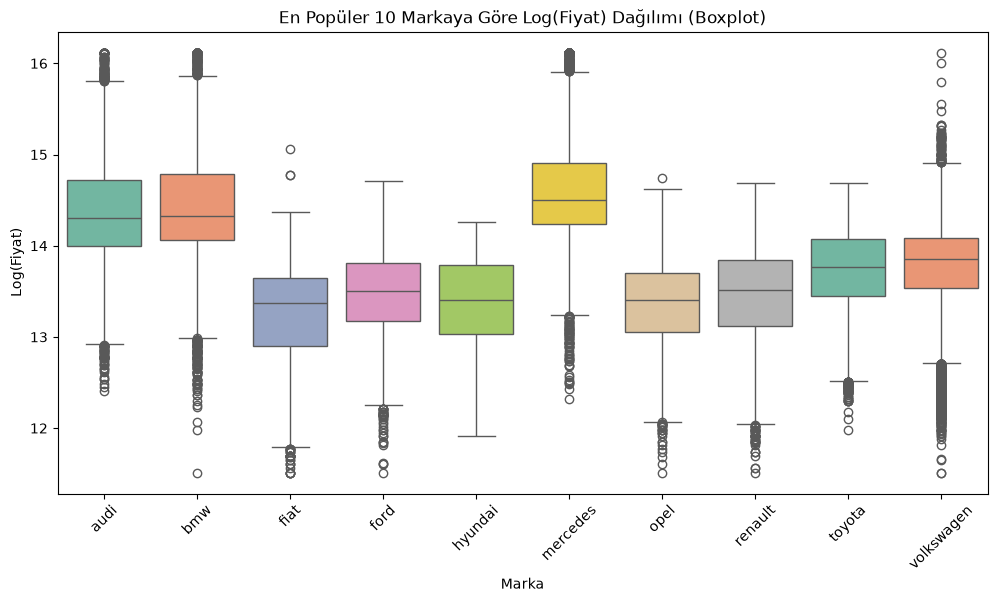

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# v2 temiz verimizi yükleyelim
clean = pd.read_csv("../data/processed/arac_temiz_v2.csv")

# Markalara göre araç sayıları ve ortalama fiyatlar (İlk 15 marka)
marka_analiz = clean.groupby("brand").agg(
    ilan_sayisi=("price", "count"),
    ortalama_fiyat=("price", "mean"),
    medyan_fiyat=("price", "median")
).sort_values(by="ilan_sayisi", ascending=False).head(15)

print("--- En Çok İlanı Bulunan İlk 15 Marka ve Fiyat İstatistikleri (TL) ---")
print(marka_analiz.round(2))

# Görselleştirme: İlk 10 markanın medyan fiyatları
plt.figure(figsize=(12, 6))
top_brands = clean["brand"].value_counts().head(10).index
sns.boxplot(data=clean[clean["brand"].isin(top_brands)], x="brand", y="log_price", palette="Set2")
plt.title("En Popüler 10 Markaya Göre Log(Fiyat) Dağılımı (Boxplot)")
plt.xticks(rotation=45)
plt.xlabel("Marka")
plt.ylabel("Log(Fiyat)")
plt.show()

In [17]:
v2 = pd.read_csv("../data/processed/arac_temiz_v2.csv")

ust = v2["price"] == 10_000_000
ref = (v2[~ust].groupby(["brand", "model", "year"])["price"]
               .agg(ref_medyan="median", n="size"))

t = v2[ust].join(ref, on=["brand", "model", "year"])
t = t[t["n"] >= 5].copy()          # en az 5 karşılaştırma ilanı olanlar
t["oran"] = t["price"] / t["ref_medyan"]

print(len(t), "ilan karşılaştırılabildi")
print(t["oran"].describe(percentiles=[.1, .25, .5, .75, .9]))

cols = ["brand", "model", "variant", "year", "km", "ref_medyan", "oran"]
t.sort_values("oran", ascending=False)[cols].head(15)

88 ilan karşılaştırılabildi
count    88.000000
mean      1.816830
std       1.412741
min       1.139601
10%       1.162791
25%       1.291156
50%       1.587932
75%       2.129925
90%       2.134472
max      14.285714
Name: oran, dtype: float64


,brand,model,variant,year,km,ref_medyan,oran
216361,volkswagen,golf,1.6 Trendline,2009,240000,700000.0,14.285714
117230,mercedes,s,S 500 500 L,2011,68000,3050000.0,3.278689
112811,mercedes,c,C 63 AMG,2023,193500,4000000.0,2.500000
112810,mercedes,c,C 63 AMG,2023,41900,4000000.0,2.500000
112967,mercedes,c,C 63 AMG,2024,85400,4350000.0,2.298851
112968,mercedes,c,C 63 AMG,2024,0,4350000.0,2.298851
28920,bmw,i,i7 xDrive60 M Excellence,2023,79000,4685000.0,2.134472
28923,bmw,i,i7 xDrive60 M Excellence,2023,8500,4685000.0,2.134472
28939,bmw,i,i7 xDrive60 M Excellence,2023,0,4685000.0,2.134472
28935,bmw,i,i7 xDrive60 M Excellence,2023,0,4685000.0,2.134472


In [18]:
bil = v2_yakit[v2_yakit["yakit_tipi"] == "Bilinmiyor"]   # kendi yakıt sütununu içeren dataframe
print(bil["brand"].value_counts().head(8))
bil[["brand", "model", "variant"]].sample(40, random_state=7)

NameError: name 'v2_yakit' is not defined

In [19]:
print(v2.columns.tolist())   # "yakit_tipi" listede var mı?

['brand', 'model', 'variant', 'year', 'km', 'color', 'price', 'city', 'log_price', 'yakit_tipi']


In [20]:
v2["km_kirpildi"] = (v2["km"] == 300000).astype(int)
v2["km_kirpildi"].value_counts()

km_kirpildi
0    249775
1      1685
Name: count, dtype: int64

In [21]:
v2 = pd.read_csv("../data/processed/arac_temiz_v2.csv")

print("Satır:", len(v2))                           # 251.391 beklenir
print("km == 0:", (v2["km"] == 0).sum())           # 0 beklenir
print("Mükerrer:", v2.duplicated().sum())          # 0 beklenir
print("year < 1995:", (v2["year"] < 1995).sum())   # 0 beklenir
print("km == 300000:", (v2["km"] == 300000).sum()) # 1.784 civarı beklenir

print()
print(v2["yakit_tipi"].value_counts(dropna=False))

Satır: 251460
km == 0: 72
Mükerrer: 0
year < 1995: 0
km == 300000: 1685

yakit_tipi
Dizel              104590
Bilinmiyor          95946
Benzin              43414
LPG                  4056
Hibrit/Elektrik      3454
Name: count, dtype: int64
